# CSE558 - Data Science Assignment : JL with K-Means

## Importing all Required Libraries

In [ ]:
from sklearn.datasets import fetch_kddcup99
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
import time
encoder = OneHotEncoder(sparse_output=False)
# random.seed(67)

## Loading Dataset

In [ ]:
kdd = fetch_kddcup99(subset=None, as_frame=True)

## Preparing the data

In [ ]:
D = kdd.data

print("Before: ")
print("protocol_type",D["protocol_type"].shape)
print("service",D["service"].shape)
print("flag",D["flag"].shape)
print()
print("Matrix Size: ", D.shape)

convert_to_float = FunctionTransformer(lambda x: x.astype(float))
columns_ohe = ["protocol_type","service","flag"]
ct = ColumnTransformer(transformers=[('encoder',encoder,columns_ohe)],remainder=convert_to_float)

new_D = ct.fit_transform(D)
print("Matrix Size After encoding, and float conversion: ",new_D.shape)

# Dropping const colums
const_cols = []
for i in range(new_D.shape[1]):
  col = new_D[:,i]
  if len(np.unique(col))==1:
    const_cols.append(i)

new_D = np.delete(new_D,const_cols,axis=1)
print("Matrix Size After Dropping: ",new_D.shape)

col_min = new_D.min(axis=0)
col_max = new_D.max(axis=0)
col_range = col_max - col_min
col_range[col_range == 0] = 1
new_D = (new_D - col_min) / col_range

print("Matrix Size After Rescaling: ",new_D.shape)

# for the record.
print("Number of Rows: ",new_D.shape[0])
print("NUmber of Columns: ",new_D.shape[1])

Before: 
protocol_type (494021,)
service (494021,)
flag (494021,)

Matrix Size:  (494021, 41)
Matrix Size After encoding, and float conversion:  (494021, 118)
Matrix Size After Dropping:  (494021, 116)
Matrix Size After Rescaling:  (494021, 116)
Number of Rows:  494021
NUmber of Columns:  116


## The Model

In [ ]:
model = KMeans(n_clusters=15,n_init=5,random_state=67)

Q1 (a)

In [ ]:
t0 = time.perf_counter()
model.fit(new_D)
elapsed = time.perf_counter() - t0
print("Wall clock time: ",elapsed)

Wall clock time:  21.52425727700006


In [ ]:
print(model)
org_cost = model.inertia_
org_labels = model.labels_
org_cluster_centers = model.cluster_centers_
print("Sum of Squared distance from each point to its closest center, COST (D,B) =",org_cost)

KMeans(n_clusters=15, n_init=5, random_state=67)
Sum of Squared distance from each point to its closest center, COST (D,B) = 53230.529969786636


Q1 (b), (c)

In [ ]:
model1 = KMeans(n_clusters=15,n_init=5,random_state=67)

In [ ]:
def computeCost(D,B):
  best = np.full(D.shape[0], np.inf)
  for i in range(len(B)):
    best = np.minimum(best,(np.linalg.norm(D-B[i],axis=1)**2))
  cost = 0
  for i in best:
    cost+=i
  return cost

In [ ]:
m = [5,10,15,20,25]
A = []
costr = []
costr_plus = []
t = []
for i in range(len(m)):
  rng = np.random.default_rng((i+1)*100)
  mid = []
  costr_i = []
  costr_plus_i = []
  t_i = []
  for j in range(5):
    t0 = time.perf_counter()
    x = rng.normal(loc=0, scale=1/np.sqrt(m[i]), size=(m[i],new_D.shape[1]))
    E = np.matmul(new_D,np.matrix_transpose(x))
    model1.fit(E)
    t_i.append(time.perf_counter()-t0)
    B_hat = []
    C_E = model1.labels_
    A_plus = np.linalg.pinv(x)
    B_plus = model1.cluster_centers_ @ A_plus.T
    plus_cost = computeCost(new_D,B_plus)
    costr_plus_i.append(plus_cost/org_cost)
    for k in np.unique(C_E):
      row_j = new_D[C_E == k]
      B_hat.append(row_j.mean(axis=0))
    B_hat = np.array(B_hat)
    new_cost = computeCost(new_D,B_hat)
    costr_i.append(new_cost/org_cost)
    mid.append(x)
  costr.append(costr_i)
  costr_plus.append(costr_plus_i)
  t.append(t_i)
  A.append(mid)
print(costr)
print(costr_plus)
print(t)

[[np.float64(1.1629260553320175), np.float64(1.1935041411458749), np.float64(1.045176939450767), np.float64(1.2085891987440647), np.float64(1.1528077109075872)], [np.float64(1.048998549597005), np.float64(1.1570438526515818), np.float64(1.1000753742765288), np.float64(1.036663641147289), np.float64(1.1462351382094023)], [np.float64(1.01309871942948), np.float64(1.0327617449833306), np.float64(1.042954624458481), np.float64(1.0769134874646384), np.float64(1.050850121050422)], [np.float64(1.005469400023444), np.float64(1.056811365353775), np.float64(1.04377220806955), np.float64(1.0602175312209723), np.float64(1.0261211606344538)], [np.float64(1.1082513193175745), np.float64(0.97298990982187), np.float64(1.0391551842381794), np.float64(1.0179419746035663), np.float64(1.0785052120021852)]]
[[np.float64(81.71838770494792), np.float64(80.96810987940626), np.float64(79.46416173823413), np.float64(81.28141034432784), np.float64(81.45166014531307)], [np.float64(78.27767321052862), np.float64(7

 m     mean      min      max
 5 1.152601 1.045177 1.208589
10 1.097803 1.036664 1.157044
15 1.043316 1.013099 1.076913
20 1.038478 1.005469 1.060218
25 1.043369 0.972990 1.108251


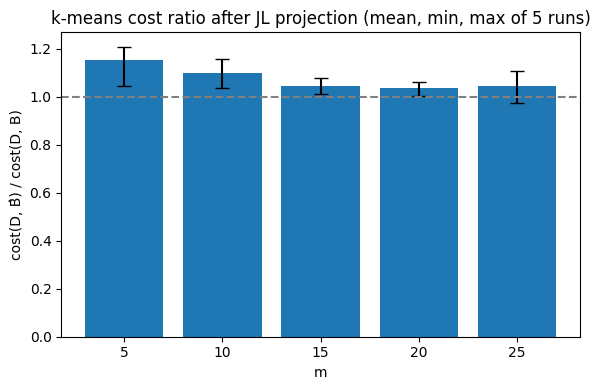

In [ ]:
ratios = np.array(costr)
mean_r = ratios.mean(axis=1)
min_r  = ratios.min(axis=1)
max_r  = ratios.max(axis=1)

table = pd.DataFrame({"m": m, "mean": mean_r, "min": min_r, "max": max_r})
print(table.to_string(index=False))

yerr = np.array([mean_r - min_r, max_r - mean_r])
plt.figure(figsize=(6, 4))
plt.bar([str(v) for v in m], mean_r, yerr=yerr, capsize=5)
plt.axhline(1, linestyle="--", color="gray")
plt.xlabel("m")
plt.ylabel("cost(D, B̂) / cost(D, B)")
plt.title("k-means cost ratio after JL projection (mean, min, max of 5 runs)")
plt.tight_layout()
plt.show()

 m  B_hat mean  B_hat min  B_hat max  B_plus mean  B_plus min  B_plus max
 5    1.152601   1.045177   1.208589    80.976746   79.464162   81.718388
10    1.097803   1.036664   1.157044    77.650237   75.914712   79.179485
15    1.043316   1.013099   1.076913    72.659531   70.901348   74.388627
20    1.038478   1.005469   1.060218    69.110584   65.825968   74.287942
25    1.043369   0.972990   1.108251    65.333022   63.489335   67.894265


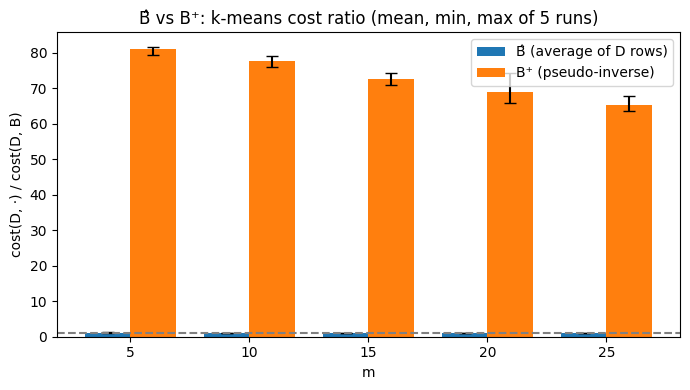

In [ ]:
ratios_hat  = np.array(costr)     # B-hat, shape (5, 5)
ratios_plus = np.array(costr_plus)     # B-plus, shape (5, 5)

table_c = pd.DataFrame({
    "m": m,
    "B_hat mean":  ratios_hat.mean(axis=1),
    "B_hat min":   ratios_hat.min(axis=1),
    "B_hat max":   ratios_hat.max(axis=1),
    "B_plus mean": ratios_plus.mean(axis=1),
    "B_plus min":  ratios_plus.min(axis=1),
    "B_plus max":  ratios_plus.max(axis=1),
})
print(table_c.to_string(index=False))

# grouped bars: mean with min..max error bars
xpos = np.arange(len(m))
w = 0.38
def err(r): return np.array([r.mean(axis=1) - r.min(axis=1), r.max(axis=1) - r.mean(axis=1)])

plt.figure(figsize=(7, 4))
plt.bar(xpos - w/2, ratios_hat.mean(axis=1),  w, yerr=err(ratios_hat),  capsize=4, label="B̂ (average of D rows)")
plt.bar(xpos + w/2, ratios_plus.mean(axis=1), w, yerr=err(ratios_plus), capsize=4, label="B⁺ (pseudo-inverse)")
plt.axhline(1, linestyle="--", color="gray")
plt.xticks(xpos, [str(v) for v in m])
plt.xlabel("m")
plt.ylabel("cost(D, ·) / cost(D, B)")
plt.title("B̂ vs B⁺: k-means cost ratio (mean, min, max of 5 runs)")
plt.legend()
plt.tight_layout()
plt.show()

 m  mean time (s)
 5       5.153561
10       5.824489
15       7.949919
20       7.719780
25       8.048062
k-means on D (a): 21.52425727700006 s


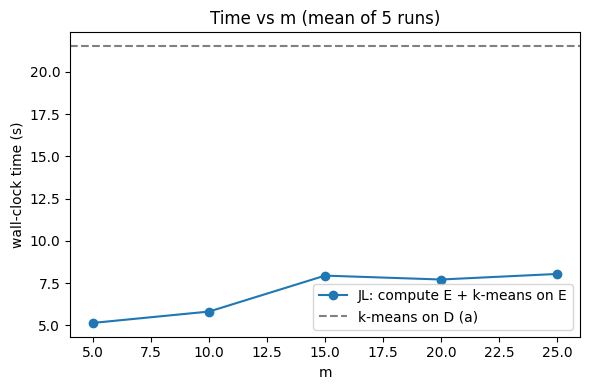

In [ ]:
times = np.array(t)                 # shape (5, 5)
mean_t = times.mean(axis=1)

table_t = pd.DataFrame({"m": m, "mean time (s)": mean_t})
print(table_t.to_string(index=False))
print("k-means on D (a):", elapsed, "s")

plt.figure(figsize=(6, 4))
plt.plot(m, mean_t, marker="o", label="JL: compute E + k-means on E")
plt.axhline(elapsed, linestyle="--", color="gray", label="k-means on D (a)")
plt.xlabel("m")
plt.ylabel("wall-clock time (s)")
plt.title("Time vs m (mean of 5 runs)")
plt.legend()
plt.tight_layout()
plt.show()

Q (e)

In [ ]:
n = new_D.shape[0]
N = 10000
rng1 = np.random.default_rng(67)

I = rng1.integers(0, n, size=2*N)
L = rng1.integers(0, n, size=2*N)

diff = (new_D[I] != new_D[L]).any(axis=1)
I,L = I[diff][:N], L[diff][:N]
print(len(I),len(L))


den = (np.linalg.norm(new_D[I] - new_D[L],axis=1) ** 2)

ratio_i = []
diffs = new_D[I] - new_D[L]
for i in range(len(m)):
    Ai = A[i][0]
    Ed = diffs @ Ai.T
    num = (Ed ** 2).sum(axis=1)
    ratio_i.append(num / den)
    print(m[i], ratio_i[-1].mean(), ratio_i[-1].std())


10000 10000
5 0.6195528848728858 0.39930727020888535
10 1.0233384804129908 0.378298711816094
15 1.0004341930029013 0.2987037782028486
20 1.1675766907969665 0.329363083853176
25 0.8934209895858765 0.2614860233921176


In [ ]:
def costPartition(X,labels,k=15):
  total = 0.0
  for i in range(k):
    Xj = X[labels==i]
    total+=np.linalg.norm(Xj-Xj.mean(axis=0))**2
  return total

In [ ]:
ratio_ii = []
our_cost = costPartition(new_D, org_labels)
for mv in m:
    r = []
    for _ in range(20):
        Ad = rng1.normal(0, 1 / np.sqrt(mv), size=(mv, new_D.shape[1]))
        E = new_D @ Ad.T
        r.append(costPartition(E, org_labels) / our_cost)
    ratio_ii.append(r)
    print(mv, np.mean(r), np.std(r))

5 1.032412694143554 0.12257056298527592
10 1.002267731622371 0.10478161984262033
15 0.9945899004989684 0.07821476136680473
20 1.012004369678826 0.0600067170092986
25 1.0156673115250716 0.07735019358022008


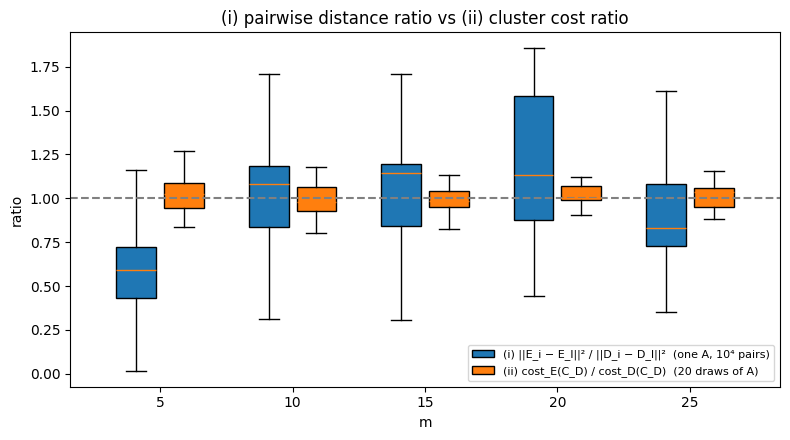

In [ ]:
pos = np.arange(len(m))
plt.figure(figsize=(8, 4.5))
b1 = plt.boxplot(ratio_i,  positions=pos - 0.18, widths=0.3, patch_artist=True, showfliers=False)
b2 = plt.boxplot(ratio_ii, positions=pos + 0.18, widths=0.3, patch_artist=True, showfliers=False)
for patch in b1["boxes"]: patch.set_facecolor("tab:blue")
for patch in b2["boxes"]: patch.set_facecolor("tab:orange")
plt.axhline(1, linestyle="--", color="gray")
plt.xticks(pos, [str(v) for v in m])
plt.xlabel("m")
plt.ylabel("ratio")
plt.title("(i) pairwise distance ratio vs (ii) cluster cost ratio")
plt.legend([b1["boxes"][0], b2["boxes"][0]],
           ["(i) ||E_i − E_l||² / ||D_i − D_l||²  (one A, 10⁴ pairs)",
            "(ii) cost_E(C_D) / cost_D(C_D)  (20 draws of A)"], fontsize=8)
plt.tight_layout()
plt.show()